# Generalised dimensions of a multiplicative cascade

A multiplicative cascade splits a cube into eight octants, gives them the
fractions $w_1, \dots, w_8$ of its mass, and repeats this in every octant down
to a finest level. Its generalised dimensions are known exactly:

$$D_q = \frac{\tau(q)}{q - 1}, \qquad \tau(q) = -\log_2 \sum_{i} w_i^{\,q},$$

so it is a good test of an estimator. Here we use the *random* cascade of
`pyrenyi.mocks.random_cascade`, in which every cell assigns the weights to its
octants in an independent random order, so the point distribution is
statistically homogeneous. We sample it with points, measure $D_q$ with the
fixed-radius and fixed-mass estimators of PyRenyi, and compare with the exact
curve.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, NullFormatter, ScalarFormatter

import pyrenyi

# categorical colours (fixed order) and markers for the orders q
COLOURS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']
MARKERS = ['o', 's', '^', 'D']
INK = '#1a1a19'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e6e6e3', 'grid.linewidth': 0.6,
                     'axes.axisbelow': True, 'legend.frameon': False})


def radius_axis(ax, ticks):
    # logarithmic radius axis with plain tick labels
    ax.set_xscale('log')
    ax.xaxis.set_major_locator(FixedLocator(ticks))
    ax.xaxis.set_major_formatter(ScalarFormatter())
    ax.xaxis.set_minor_formatter(NullFormatter())

## The point distribution

A million points from a ten-level cascade in a periodic box of side 1000, so
that the cascade is self-similar between about 1 and 1000. The map below is
the density of the points projected along $z$, which is itself a
two-dimensional cascade.

/tmp/ipykernel_1955116/3850346403.py:7: RuntimeWarning: divide by zero encountered in log10
  im = ax.imshow(np.log10(counts.T / counts.mean()), origin='lower', extent=(0, L, 0, L),


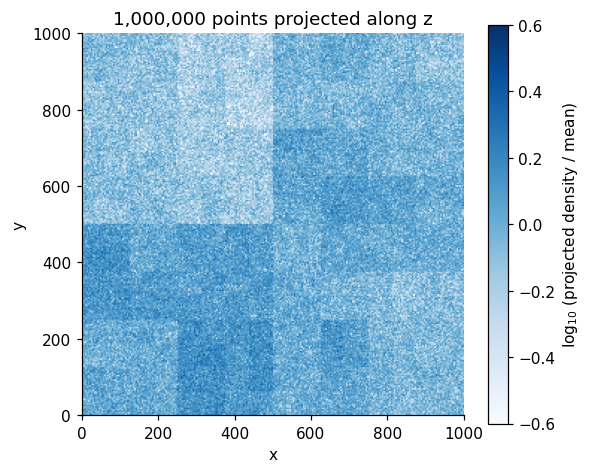

In [2]:
L = 1000.0
w = [0.16, 0.15, 0.14, 0.13, 0.12, 0.11, 0.10, 0.09]          # octant weights
x = pyrenyi.mocks.random_cascade(1_000_000, w, levels=10, box=L, seed=1)

counts, _, _ = np.histogram2d(x[:, 0], x[:, 1], bins=256, range=[[0, L], [0, L]])
fig, ax = plt.subplots(figsize=(5.6, 4.8))
im = ax.imshow(np.log10(counts.T / counts.mean()), origin='lower', extent=(0, L, 0, L),
               cmap='Blues', vmin=-0.6, vmax=0.6)
fig.colorbar(im, ax=ax, label='log$_{10}$ (projected density / mean)')
ax.set(xlabel='x', ylabel='y', title=f'{len(x):,} points projected along z')
ax.grid(False)
plt.show()

## The exact generalised dimensions

The weights span a factor 1.8, a mild multifractal: $D_q$ falls from about 3.1
at $q = -4$ to 2.9 at $q = 6$, and $D_0 = 3$ because every octant is occupied.

In [3]:
q = np.arange(-4.0, 6.01, 0.5)
q_fine = np.linspace(-4.0, 6.0, 201)
exact = pyrenyi.mocks.cascade_dq(w, q)
exact_fine = pyrenyi.mocks.cascade_dq(w, q_fine)
for qq, d in zip(q[::2], exact[::2]):
    print(f'q = {qq:5.1f}   D_q = {d:.4f}')

q =  -4.0   D_q = 3.1010
q =  -3.0   D_q = 3.0764
q =  -2.0   D_q = 3.0510
q =  -1.0   D_q = 3.0253
q =   0.0   D_q = 3.0000
q =   1.0   D_q = 2.9755
q =   2.0   D_q = 2.9523
q =   3.0   D_q = 2.9307
q =   4.0   D_q = 2.9109
q =   5.0   D_q = 2.8928
q =   6.0   D_q = 2.8765


## Fixed-radius estimator

`pyrenyi.measure` counts the neighbours of every point within each radius,
applies Grassberger's finite-sample correction, and returns the Rényi
functionals $Y_q(r)$; `dq()` gives the local slopes
$D_q(r) = dY_q/d\ln r$ between adjacent radii. The jackknife errors come from
27 sub-boxes.

In [4]:
radii = 5.0 * 2.0 ** (np.arange(15) / 3.0)          # 5 to 127, three per octave
fr = pyrenyi.measure(x, radii=radii, q=q, box=L, jackknife=27)
D, r = fr.dq()
E = fr.errors()
fr

RenyiResult(point, 21 q, 15 radii, 27 jackknife regions)

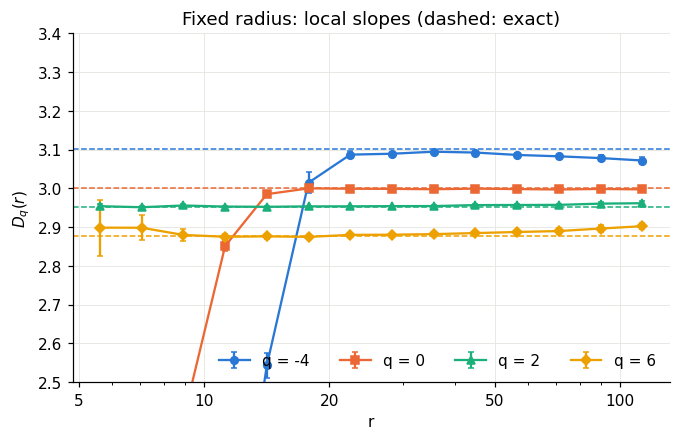

In [5]:
show = [-4.0, 0.0, 2.0, 6.0]
fig, ax = plt.subplots(figsize=(7, 4.2))
for c, m, qq in zip(COLOURS, MARKERS, show):
    i = int(np.flatnonzero(q == qq)[0])
    ax.errorbar(r, D[i], E[i], color=c, marker=m, ms=5, lw=1.5, capsize=2, label=f'q = {qq:g}')
    ax.axhline(exact[i], color=c, lw=1, ls='--')
radius_axis(ax, [5, 10, 20, 50, 100])
ax.set(ylim=(2.5, 3.4), xlabel='r', ylabel='$D_q(r)$',
       title='Fixed radius: local slopes (dashed: exact)')
ax.legend(ncol=4, loc='lower right')
plt.show()

Above $r \simeq 20$ every order is within about 0.01 of the exact value; at
the largest radii, a tenth of the box, the slopes drift slightly towards 3
because the box holds a fixed total mass. At small radii the spheres hold only
a few points, and the negative orders, which weight the emptiest spheres, are
biased low: the finite-sample correction is exact only for integer $q \ge 2$.
Integer orders such as $q = 2$ are unbiased at every radius.

## Fixed-mass estimator

`pyrenyi.fixed_mass` instead uses the distance to the $k$-th neighbour of each
point. For any Poisson-sampled field the expected number of neighbours within
that distance follows a Gamma($k$) law, which gives an estimator without
discreteness bias at every $q$, including $q < 0$. $D_q$ is returned between
adjacent $k$, at their typical radius.

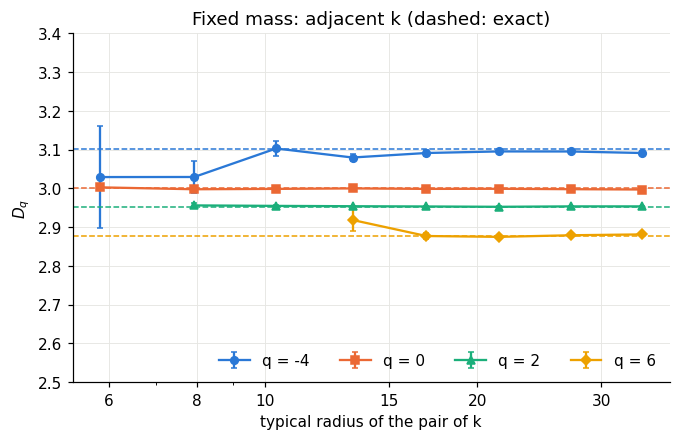

In [6]:
k = 2 ** np.arange(9)                                 # 1 to 256 neighbours
fm = pyrenyi.fixed_mass(x, k=k, q=q, box=L, jackknife=27)
Dm, rm = fm.dq()
Em = fm.errors()

fig, ax = plt.subplots(figsize=(7, 4.2))
for c, m, qq in zip(COLOURS, MARKERS, show):
    i = int(np.flatnonzero(q == qq)[0])
    ax.errorbar(rm, Dm[i], Em[i], color=c, marker=m, ms=5, lw=1.5, capsize=2, label=f'q = {qq:g}')
    ax.axhline(exact[i], color=c, lw=1, ls='--')
radius_axis(ax, [6, 8, 10, 15, 20, 30])
ax.set(ylim=(2.5, 3.4), xlabel='typical radius of the pair of k',
       ylabel='$D_q$', title='Fixed mass: adjacent k (dashed: exact)')
ax.legend(ncol=4, loc='lower right')
plt.show()

The fixed-mass estimates follow the exact values down to the smallest scales
for every order. $D_q$ needs $q < k + 1$, so the highest orders start at larger
$k$, and they are noisier at small $k$, where they rest on the closest pairs.

## $D_q$ against $q$

Finally, both estimators over two octaves of scale, well inside the range
where the cascade is self-similar: the fixed-radius slope between $r = 20$ and
$80$, and the fixed-mass estimate between $k = 16$ and $256$ (typical radii of
about 15 and 40).

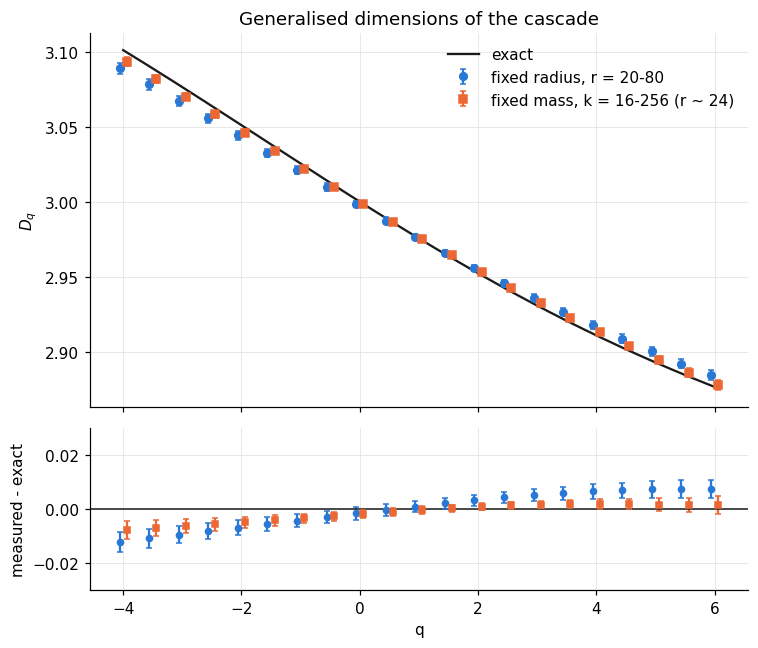

 q     exact   fixed radius      fixed mass
-4.0   3.101   3.089 +- 0.004   3.093 +- 0.003
-3.0   3.076   3.067 +- 0.003   3.070 +- 0.003
-2.0   3.051   3.044 +- 0.003   3.046 +- 0.002
-1.0   3.025   3.021 +- 0.003   3.022 +- 0.002
 0.0   3.000   2.998 +- 0.002   2.998 +- 0.002
 1.0   2.976   2.977 +- 0.002   2.975 +- 0.001
 2.0   2.952   2.956 +- 0.002   2.953 +- 0.001
 3.0   2.931   2.936 +- 0.002   2.932 +- 0.001
 4.0   2.911   2.918 +- 0.003   2.913 +- 0.002
 5.0   2.893   2.900 +- 0.003   2.895 +- 0.002
 6.0   2.877   2.884 +- 0.003   2.878 +- 0.003


In [7]:
# fixed radius: slope of Y_q between two radii, with its jackknife error
i1, i2 = 6, 12                                        # r = 20 and 80
Y, Yjk = fr.Yq(), fr.Yq(jackknife=True)
lr = np.log(radii[i2] / radii[i1])
D_fr = (Y[:, i2] - Y[:, i1]) / lr
D_fr_jk = (Yjk[:, :, i2] - Yjk[:, :, i1]) / lr
E_fr = np.sqrt(np.diag(pyrenyi.jackknife_covariance(D_fr_jk)))

# fixed mass: one pair spanning the range
D_fm, r_fm = fm.dq(pairs=[(16, 256)])
E_fm = fm.errors(pairs=[(16, 256)])
D_fm, E_fm = D_fm[:, 0], E_fm[:, 0]

fig, (ax, ax2) = plt.subplots(2, 1, figsize=(7, 6), sharex=True,
                              gridspec_kw={'height_ratios': [3, 1.3]})
ax.plot(q_fine, exact_fine, color=INK, lw=1.5, label='exact')
ax.errorbar(q - 0.06, D_fr, E_fr, color=COLOURS[0], marker='o', ms=5, ls='none', capsize=2,
            label=f'fixed radius, r = {radii[i1]:.0f}-{radii[i2]:.0f}')
ax.errorbar(q + 0.06, D_fm, E_fm, color=COLOURS[1], marker='s', ms=5, ls='none', capsize=2,
            label=f'fixed mass, k = 16-256 (r ~ {r_fm[0]:.0f})')
ax.set(ylabel='$D_q$', title='Generalised dimensions of the cascade')
ax.legend()
ax2.axhline(0, color=INK, lw=1)
ax2.errorbar(q - 0.06, D_fr - exact, E_fr, color=COLOURS[0], marker='o', ms=4, ls='none', capsize=2)
ax2.errorbar(q + 0.06, D_fm - exact, E_fm, color=COLOURS[1], marker='s', ms=4, ls='none', capsize=2)
ax2.set(xlabel='q', ylabel='measured - exact', ylim=(-0.03, 0.03))
fig.tight_layout()
plt.show()

print(' q     exact   fixed radius      fixed mass')
for i in range(0, len(q), 2):
    print(f'{q[i]:4.1f}   {exact[i]:.3f}   {D_fr[i]:.3f} +- {E_fr[i]:.3f}   {D_fm[i]:.3f} +- {E_fm[i]:.3f}')

Both estimators recover the exact $D_q$ to about 0.01 at every $q$ from $-4$
to $6$. The small residual tilt, largest at the extreme orders, is shared by
the two estimators and by other random seeds. It is systematic rather than
noise: spheres centred on points sample a cascade built on cubes over a finite
range of scales. The jackknife errors measure only the sampling noise of this
realisation, so they do not cover it.

For a real survey, pass a random catalogue as the second argument of `measure`
or `fixed_mass`; see `examples/survey.py`.